# Proteome prediction figures — GNN+QSAR

This notebook loads the 465k in-silico proteome set, the 50k MAPP set, and the 1k confirmed-candidate set. All prediction analysis uses **GNN+QSAR only**. The 10 paper-selected candidates are listed as their own set and marked on each distribution that contains them.

In [250]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["font.family"] = "monospace"
plt.rcParams["pdf.fonttype"] = 42

SPINE_COLOR = "#2b2b2b"
MODEL_COLOR = "#1f77b4"
MODEL_NAME = "GNN+QSAR"
MODEL_ALIASES = ("GNN+QSAR", "GNN+QSAR12", "ESM+QSAR12", "VAE+QSAR12")
MODEL_SUFFIXES = (
    "_pred",
    "_prob_AMP",
    "_confidence",
    "_score_z",
    "_logit_AMP",
    "_logit_nonAMP",
    "_logit_margin",
    "_hyperplane_distance",
    "_distance",
)

PAPER_COLOR = "#c0392b"
PAPER_CANDIDATES = {
    "SLVTKKKRFWCWQRPKYQFL": "DFNA5",
    "SQLYPRHKHLLIKRSLRCRKC": "DCTN4",
    "MRAKWRKKRMRRLK": "RPL41",
    "RSIFIKYKSKPFCEKLLSWVKS": "PSMG2",
    "SRVPRFYWKDRLLKMKMA": "GLB1",
    "LPLIIFLRNRLKY": "RPS4X",
    "KRRFNIKLWKTF": "PPP1CB",
    "RRYVRKFVLMR": "CHMP2A",
    "SRGLRYYYDKNIIHKTAGKRYVYRFV": "ETS1",
    "GHQQLYWSHPRKFGQGSRSCRVCSNRHGLIRKYGLNM": "RPS29",
}

DATASET_CONFIGS = {
    "465k": {
        "name": "In-silico proteome candidates",
        "path": "sequence_to_svm_minimal/data/proteomes/gnn_predictions/generated/model_comparison_latest.csv",
    },
    "50k": {
        "name": "MAPP candidates",
        "path": "sequence_to_svm_minimal/data/test/mass_spec_dedup/generated/model_comparison_latest.csv",
        "metadata_path": "sequence_to_svm_minimal/data/test/mass_spec_dedup/dedup_MAPP.csv",
    },
    "1k": {
        "name": "Confirmed candidates",
        "path": "sequence_to_svm_minimal/data/proteomes/confirmed_candidates/generated/model_comparison_latest.csv",
    },
}

In [251]:
def find_project_root() -> Path:
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / "sequence_to_svm_minimal").is_dir():
            return candidate
    raise FileNotFoundError("Could not locate the repository root from the current working directory.")


def find_column(frame: pd.DataFrame, names: tuple[str, ...]) -> str | None:
    by_lower = {column.lower(): column for column in frame.columns}
    return next((by_lower[name.lower()] for name in names if name.lower() in by_lower), None)


def model_suffix(column: str) -> str | None:
    return next((suffix for suffix in MODEL_SUFFIXES if column.endswith(suffix)), None)


def canonicalize_qsar_columns(frame: pd.DataFrame) -> pd.DataFrame:
    result = frame.copy()
    for suffix in MODEL_SUFFIXES:
        target = f"{MODEL_NAME}{suffix}"
        if target not in result.columns:
            source = next(
                (f"{alias}{suffix}" for alias in MODEL_ALIASES if f"{alias}{suffix}" in result.columns),
                None,
            )
            if source is not None:
                result[target] = result[source]

    keep = []
    for column in result.columns:
        suffix = model_suffix(column)
        if suffix is None or column[: -len(suffix)] == MODEL_NAME:
            keep.append(column)
    return result.loc[:, keep]


def progress_prediction_paths(result_path: Path) -> list[Path]:
    progress_dir = result_path.parent / "compare_progress"
    if not progress_dir.is_dir():
        return []
    return sorted(path for path in progress_dir.glob("*_predictions.csv") if "qsar" in path.stem.lower())


def merge_progress_predictions(frame: pd.DataFrame, progress_path: Path) -> pd.DataFrame:
    progress = pd.read_csv(progress_path)
    id_column = find_column(frame, ("peptide_id", "id"))
    if id_column is None or not {"peptide_id", "prob_amp"}.issubset(progress.columns):
        return frame

    rename = {
        "pred": f"{MODEL_NAME}_pred",
        "prob_amp": f"{MODEL_NAME}_prob_AMP",
        "logit_amp": f"{MODEL_NAME}_logit_AMP",
        "logit_nonamp": f"{MODEL_NAME}_logit_nonAMP",
        "logit_margin": f"{MODEL_NAME}_logit_margin",
    }
    available = {source: target for source, target in rename.items() if source in progress.columns}
    progress = progress[["peptide_id", *available]].copy().rename(columns=available)
    progress["peptide_id"] = progress["peptide_id"].astype(str).str.strip()
    progress = progress.drop_duplicates("peptide_id", keep="first")

    merged = frame.copy()
    merged[id_column] = merged[id_column].astype(str).str.strip()
    merged = merged.merge(
        progress,
        left_on=id_column,
        right_on="peptide_id",
        how="left",
        suffixes=("", "__progress"),
    )
    if id_column != "peptide_id":
        merged = merged.drop(columns="peptide_id")
    for target in available.values():
        progress_column = f"{target}__progress"
        if progress_column not in merged.columns:
            continue
        if target in merged.columns:
            merged[target] = merged[target].combine_first(merged[progress_column])
        else:
            merged[target] = merged[progress_column]
        merged = merged.drop(columns=progress_column)
    return merged


def join_distinct(values: pd.Series) -> str:
    cleaned = (str(value).strip() for value in values.dropna())
    return "; ".join(dict.fromkeys(value for value in cleaned if value))


def add_sequence_metadata(
    frame: pd.DataFrame,
    config: dict[str, str],
    project_root: Path,
) -> pd.DataFrame:
    sequence_column = find_column(frame, ("sequence", "peptide_sequence", "peptide"))
    if sequence_column is None:
        return frame

    result = frame.copy()
    sequence_key = result[sequence_column].astype("string").str.strip().str.upper()
    result["sequence_length"] = sequence_key.str.len().astype("Int64")
    metadata_path = config.get("metadata_path")
    if metadata_path is None:
        return result

    metadata = pd.read_csv(project_root / metadata_path)
    metadata_sequence = find_column(metadata, ("Sequence", "sequence"))
    protein_column = find_column(metadata, ("Leading razor protein", "parent_protein"))
    gene_column = find_column(metadata, ("Gene names", "gene_name"))
    if metadata_sequence is None or (protein_column is None and gene_column is None):
        return result

    rename = {
        column: target
        for column, target in (
            (protein_column, "parent_protein"),
            (gene_column, "gene_name"),
        )
        if column is not None
    }
    annotations = metadata[[metadata_sequence, *rename]].copy().rename(columns=rename)
    annotations["__sequence_key"] = (
        annotations[metadata_sequence].astype("string").str.strip().str.upper()
    )
    annotations = annotations.groupby("__sequence_key", as_index=False, sort=False).agg(
        {column: join_distinct for column in rename.values()}
    )
    result["__sequence_key"] = sequence_key
    return result.merge(annotations, on="__sequence_key", how="left").drop(columns="__sequence_key")


def load_dataset(key: str, config: dict[str, str], project_root: Path) -> pd.DataFrame:
    result_path = project_root / config["path"]
    if not result_path.is_file():
        raise FileNotFoundError(f"Missing {key} result file: {result_path}")

    frame = canonicalize_qsar_columns(pd.read_csv(result_path))
    probability_column = f"{MODEL_NAME}_prob_AMP"
    if probability_column not in frame.columns or frame[probability_column].isna().any():
        for progress_path in progress_prediction_paths(result_path):
            frame = merge_progress_predictions(frame, progress_path)
    frame = canonicalize_qsar_columns(frame)

    if probability_column not in frame.columns:
        raise KeyError(f"{MODEL_NAME} probabilities are absent from {result_path}")
    frame[probability_column] = pd.to_numeric(frame[probability_column], errors="coerce")
    frame = add_sequence_metadata(frame, config, project_root)
    frame.attrs.update(dataset_key=key, dataset_name=config["name"], source_path=str(result_path))
    return frame


def load_all_datasets() -> dict[str, pd.DataFrame]:
    project_root = find_project_root()
    return {
        key: load_dataset(key, config, project_root)
        for key, config in DATASET_CONFIGS.items()
    }

## Load all prediction sets

`prediction_results` keeps the three GNN+QSAR result tables under the keys `"465k"`, `"50k"`, and `"1k"`. The aliases `predictions_465k`, `predictions_50k`, and `predictions_1k` are ready for subsequent figures.

In [252]:
prediction_results = load_all_datasets()
predictions_465k = prediction_results["465k"]
predictions_50k = prediction_results["50k"]
predictions_1k = prediction_results["1k"]
probability_column = f"{MODEL_NAME}_prob_AMP"

summary_records = []
for key, frame in prediction_results.items():
    probabilities = frame[probability_column].dropna()
    summary_records.append(
        {
            "set": key,
            "dataset": frame.attrs["dataset_name"],
            "rows": len(frame),
            "predictions": len(probabilities),
            "missing": int(frame[probability_column].isna().sum()),
            "mean_p_amp": probabilities.mean(),
            "median_p_amp": probabilities.median(),
        }
    )

dataset_summary = pd.DataFrame(summary_records).set_index("set")
display(dataset_summary)

thresholds = (0.5, 0.8, 0.9)
threshold_count_summary = pd.DataFrame.from_dict(
    {
        key: {
            **{
                f"P(AMP) >= {threshold:.1f}": int((frame[probability_column] >= threshold).sum())
                for threshold in thresholds
            },
            "P(AMP) rounds to 1.00": int((frame[probability_column].round(2) == 1.0).sum()),
        }
        for key, frame in prediction_results.items()
    },
    orient="index",
)
threshold_count_summary.index.name = "set"
print("Counts meeting or exceeding each GNN+QSAR threshold")
display(threshold_count_summary)

,dataset,rows,predictions,missing,mean_p_amp,median_p_amp
set,,,,,,
465k,In-silico proteome candidates,465872,465872,0,0.362794,0.224649
50k,MAPP candidates,50251,50251,0,0.079147,0.027301
1k,Confirmed candidates,1074,1074,0,0.332846,0.192620


Counts meeting or exceeding each GNN+QSAR threshold


,P(AMP) >= 0.5,P(AMP) >= 0.8,P(AMP) >= 0.9,P(AMP) rounds to 1.00
set,,,,
465k,149054,82267,54903,7250
50k,1991,812,437,10
1k,303,149,86,5


## GNN+QSAR prediction distribution — 465k set

The histogram uses the full prediction set with fixed-width sigma bins. Sigma is the GNN logit margin. The solid vertical line is temperature-scaled P = 0.5, at sigma = 0. The dashed line is temperature-scaled P = 0.8. The legend, in the upper right, lists the prediction count and each threshold as Threshold P=XX, σ=XX, with the count at or above that line as N ≥ threshold count (percent). Each line is labeled P = XX on the plot, set beside the line. Gene names appear on both panels. adjustText places them just above the bars, with a line to each peptide's sigma bin. Both panels label the sigma axis. The upper panel is titled Standard Scaling and the lower panel is titled Log Scaling.

In [253]:
def style_axes(
    ax: plt.Axes,
    *,
    xlabel: str,
    ylabel: str,
    title: str,
    label_size: float = 10.5,
    title_size: float = 12,
) -> None:
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color(SPINE_COLOR)
    ax.spines["bottom"].set_color(SPINE_COLOR)
    ax.grid(False)
    ax.grid(axis="y", linestyle="--", linewidth=0.6, alpha=0.5, zorder=0)
    ax.tick_params(labelsize=8.5, length=3.5, width=0.8, colors=SPINE_COLOR)
    ax.set_xlabel(xlabel, fontsize=label_size, fontweight="bold", labelpad=6)
    ax.set_ylabel(ylabel, fontsize=label_size, fontweight="bold", labelpad=6)
    ax.set_title(title, fontsize=title_size, fontweight="bold", pad=8)


SIGMA_COLUMN = f"{MODEL_NAME}_logit_margin"
PROBABILITY_COLUMN = f"{MODEL_NAME}_prob_AMP"


def finite_numeric(frame: pd.DataFrame, column: str) -> np.ndarray:
    if column not in frame.columns:
        raise KeyError(f"{column} is absent from {frame.attrs.get('dataset_name', 'the prediction table')}.")
    values = pd.to_numeric(frame[column], errors="coerce").to_numpy(dtype=float)
    return values[np.isfinite(values)]


def paired_sigma_probability(frame: pd.DataFrame) -> tuple[np.ndarray, np.ndarray]:
    sigma = pd.to_numeric(frame[SIGMA_COLUMN], errors="coerce").to_numpy(dtype=float)
    probability = pd.to_numeric(frame[PROBABILITY_COLUMN], errors="coerce").to_numpy(dtype=float)
    mask = np.isfinite(sigma) & np.isfinite(probability)
    if int(mask.sum()) < 2:
        raise ValueError(f"Need paired {MODEL_NAME} sigma and P(AMP) values to locate the decision boundary.")
    return sigma[mask], probability[mask]


def decision_boundary_sigma(frame: pd.DataFrame, target: float = 0.5) -> float:
    """Sigma where the stored Platt calibration equals the classification probability."""
    sigma, probability = paired_sigma_probability(frame)
    probability = np.clip(probability, 1e-6, 1.0 - 1e-6)
    logit = np.log(probability / (1.0 - probability))
    slope, intercept = np.polyfit(sigma, logit, 1)
    if abs(slope) < 1e-12:
        raise ValueError("Platt slope is degenerate; cannot locate the decision boundary.")
    target_logit = np.log(target / (1.0 - target))
    return float((target_logit - intercept) / slope)


def sigma_axis_limits(frame: pd.DataFrame) -> tuple[float, float]:
    values = finite_numeric(frame, SIGMA_COLUMN)
    if values.size == 0:
        raise ValueError(f"No finite {MODEL_NAME} sigma scores are available.")
    low = float(values.min())
    high = float(values.max())
    pad = 0.02 * (high - low) if high > low else 0.5
    return low - pad, high + pad


def paper_candidate_marks(frame: pd.DataFrame) -> list[tuple[float, str]]:
    sequence_column = find_column(frame, ("sequence", "peptide_sequence", "peptide"))
    if sequence_column is None or SIGMA_COLUMN not in frame.columns:
        return []
    labels = {sequence.strip().upper(): name for sequence, name in PAPER_CANDIDATES.items()}
    keys = frame[sequence_column].astype("string").str.strip().str.upper()
    scores = pd.to_numeric(frame[SIGMA_COLUMN], errors="coerce")
    marks = []
    seen = set()
    for key, score in zip(keys, scores):
        if key in labels and key not in seen and np.isfinite(score):
            seen.add(key)
            marks.append((float(score), labels[key]))
    marks.sort(key=lambda item: item[0])
    return marks


def histogram_height(values: np.ndarray, bin_edges: np.ndarray, sigma: float) -> float:
    counts, _edges = np.histogram(values, bins=bin_edges)
    index = int(np.searchsorted(bin_edges, sigma, side="right") - 1)
    index = min(max(index, 0), len(counts) - 1)
    return float(counts[index])


def draw_paper_marks(
    axis: plt.Axes,
    marks: list[tuple[float, str]],
    values: np.ndarray,
    bin_edges: np.ndarray,
    *,
    log_y: bool,
) -> None:
    if not marks:
        return
    from adjustText import adjust_text

    ymin, ymax = axis.get_ylim()
    floor = ymin if ymin > 0 else 1.0
    texts = []
    target_x = []
    target_y = []
    starts = []
    for sigma, name in marks:
        height = histogram_height(values, bin_edges, sigma)
        tip = height if height > 0 else floor
        start = tip * 1.8 if log_y else tip + 0.06 * (ymax - ymin)
        starts.append(start)
        texts.append(
            axis.text(
                sigma,
                start,
                name,
                ha="center",
                va="bottom",
                fontsize=11,
                color=SPINE_COLOR,
                zorder=5,
            )
        )
        target_x.append(sigma)
        target_y.append(tip)
    if log_y:
        axis.set_ylim(ymin, max(ymax, max(starts) * 1.25))
    else:
        axis.set_ylim(ymin, max(ymax, max(starts) + 0.04 * (ymax - ymin)))
    adjust_text(
        texts,
        objects=list(axis.patches),
        target_x=target_x,
        target_y=target_y,
        ax=axis,
        arrowprops={"arrowstyle": "-", "color": SPINE_COLOR, "lw": 0.6},
    )


def fitted_temperature() -> float:
    import json

    path = find_project_root() / "checkpoints" / "gnn" / "gnn_vae_qsar" / "gnn_temperature_scaling"
    return float(json.loads(path.read_text())["temperature"])


def probability_sigma(probability: float, temperature: float) -> float:
    logit = np.log(probability / (1.0 - probability))
    return float(temperature * logit)


def boundary_marks(values: np.ndarray) -> list[tuple[float, str, str]]:
    temperature = fitted_temperature()
    marks = []
    for probability in (0.5, 0.8):
        sigma = probability_sigma(probability, temperature)
        count = int(np.sum(values >= sigma))
        sigma_text = "0" if abs(sigma) < 1e-8 else f"{sigma:.2f}"
        threshold = "Threshold P={:.1f}, \u03c3={}".format(probability, sigma_text)
        above = "N \u2265 threshold {:,} ({:.1%})".format(count, count / len(values))
        plot_label = "P = {:.1f}".format(probability)
        marks.append((sigma, f"{threshold}\n{above}", plot_label))
    return marks


def plot_prediction_distribution(
    frame: pd.DataFrame,
    *,
    bins: int = 100,
) -> tuple[plt.Figure, tuple[plt.Axes, plt.Axes]]:
    values = finite_numeric(frame, SIGMA_COLUMN)
    if values.size == 0:
        raise ValueError(f"No finite {MODEL_NAME} sigma scores are available.")
    low, high = sigma_axis_limits(frame)
    bin_edges = np.linspace(low, high, bins + 1)
    marks = boundary_marks(values)
    paper_marks = paper_candidate_marks(frame)
    figure, axes = plt.subplots(
        2,
        1,
        figsize=(10.0, 9.0),
        dpi=150,
        sharex=True,
        constrained_layout=True,
    )
    figure.suptitle(
        f"{MODEL_NAME} predictions | {frame.attrs['dataset_name']}",
        fontsize=12,
        fontweight="bold",
    )
    draw_sigma_panel(
        axes[0],
        values,
        bin_edges,
        marks,
        log_y=False,
        xlabel="Sigma (logit margin)",
        ylabel="Prediction count",
        title="Standard Scaling",
        histogram_label=f"Predictions (n={len(values):,})",
        paper_marks=paper_marks,
    )
    draw_sigma_panel(
        axes[1],
        values,
        bin_edges,
        marks,
        log_y=True,
        xlabel="Sigma (logit margin)",
        ylabel="Prediction count",
        title="Log Scaling",
        paper_marks=paper_marks,
    )
    return figure, (axes[0], axes[1])


def draw_sigma_panel(
    axis: plt.Axes,
    values: np.ndarray,
    bin_edges: np.ndarray,
    boundaries: list[tuple[float, str, str]],
    *,
    log_y: bool,
    xlabel: str,
    ylabel: str,
    title: str,
    histogram_label: str | None = None,
    paper_marks: list[tuple[float, str]] | None = None,
) -> None:
    axis.hist(
        values,
        bins=bin_edges,
        color=MODEL_COLOR,
        edgecolor="white",
        linewidth=0.35,
        alpha=0.85,
        label=histogram_label,
        log=log_y,
        zorder=2,
    )
    line_styles = ("-", "--")
    line_widths = (1.8, 0.8)
    for index, (sigma, label, plot_label) in enumerate(boundaries):
        axis.axvline(
            sigma,
            color="black",
            linestyle=line_styles[index % len(line_styles)],
            linewidth=line_widths[index % len(line_widths)],
            alpha=0.7,
            label=label,
            zorder=3,
        )
        axis.annotate(
            plot_label,
            xy=(sigma, 0.98),
            xycoords=axis.get_xaxis_transform(),
            xytext=(10, 0),
            textcoords="offset points",
            rotation=-90,
            rotation_mode="anchor",
            ha="left",
            va="bottom",
            fontsize=8,
            color=SPINE_COLOR,
            zorder=6,
        )
    style_axes(axis, xlabel=xlabel, ylabel=ylabel, title=title)
    axis.set_xlim(bin_edges[0], bin_edges[-1])
    axis.tick_params(axis="x", which="both", labelbottom=True)
    if not log_y:
        axis.yaxis.set_major_formatter(lambda value, _: f"{value:,.0f}")
    draw_paper_marks(axis, paper_marks or [], values, bin_edges, log_y=log_y)
    ymin, ymax = axis.get_ylim()
    if log_y and ymin > 0 and ymax > 0:
        log_span = np.log10(ymax) - np.log10(ymin)
        axis.set_ylim(ymin, 10 ** (np.log10(ymax) + 0.22 * log_span))
    elif ymax > ymin:
        axis.set_ylim(ymin, ymax + 0.22 * (ymax - ymin))
    if histogram_label is None:
        return
    legend = axis.legend(loc="upper right", fontsize=8, frameon=True, fancybox=False, framealpha=1)
    legend.get_frame().set_facecolor("white")
    legend.get_frame().set_edgecolor("#b3b3b3")
    legend.get_frame().set_linewidth(0.6)


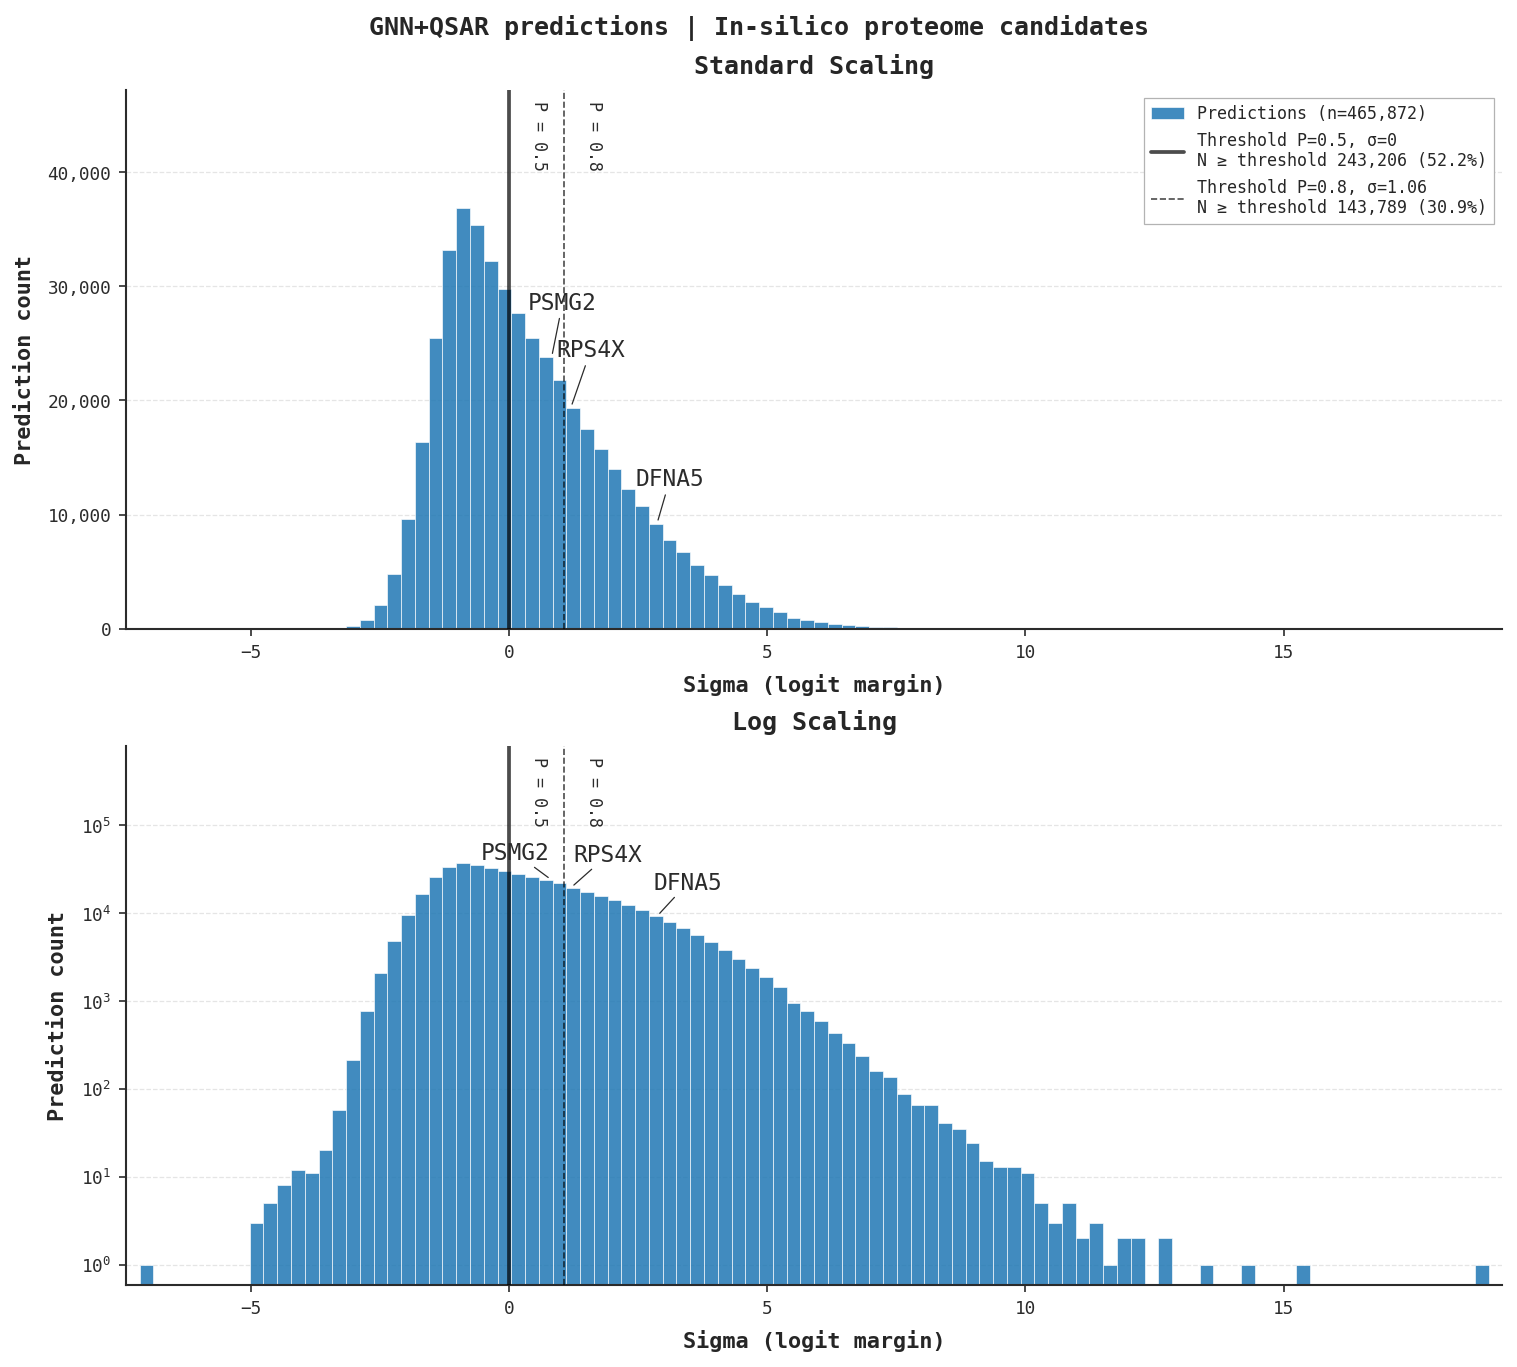

In [254]:
figure_465k, axis_465k = plot_prediction_distribution(predictions_465k)
plt.show()

## GNN+QSAR prediction distribution — MAPP set

The MAPP candidate distribution uses its own sigma range, with the same decision boundary and presentation formatting as the 465k set.

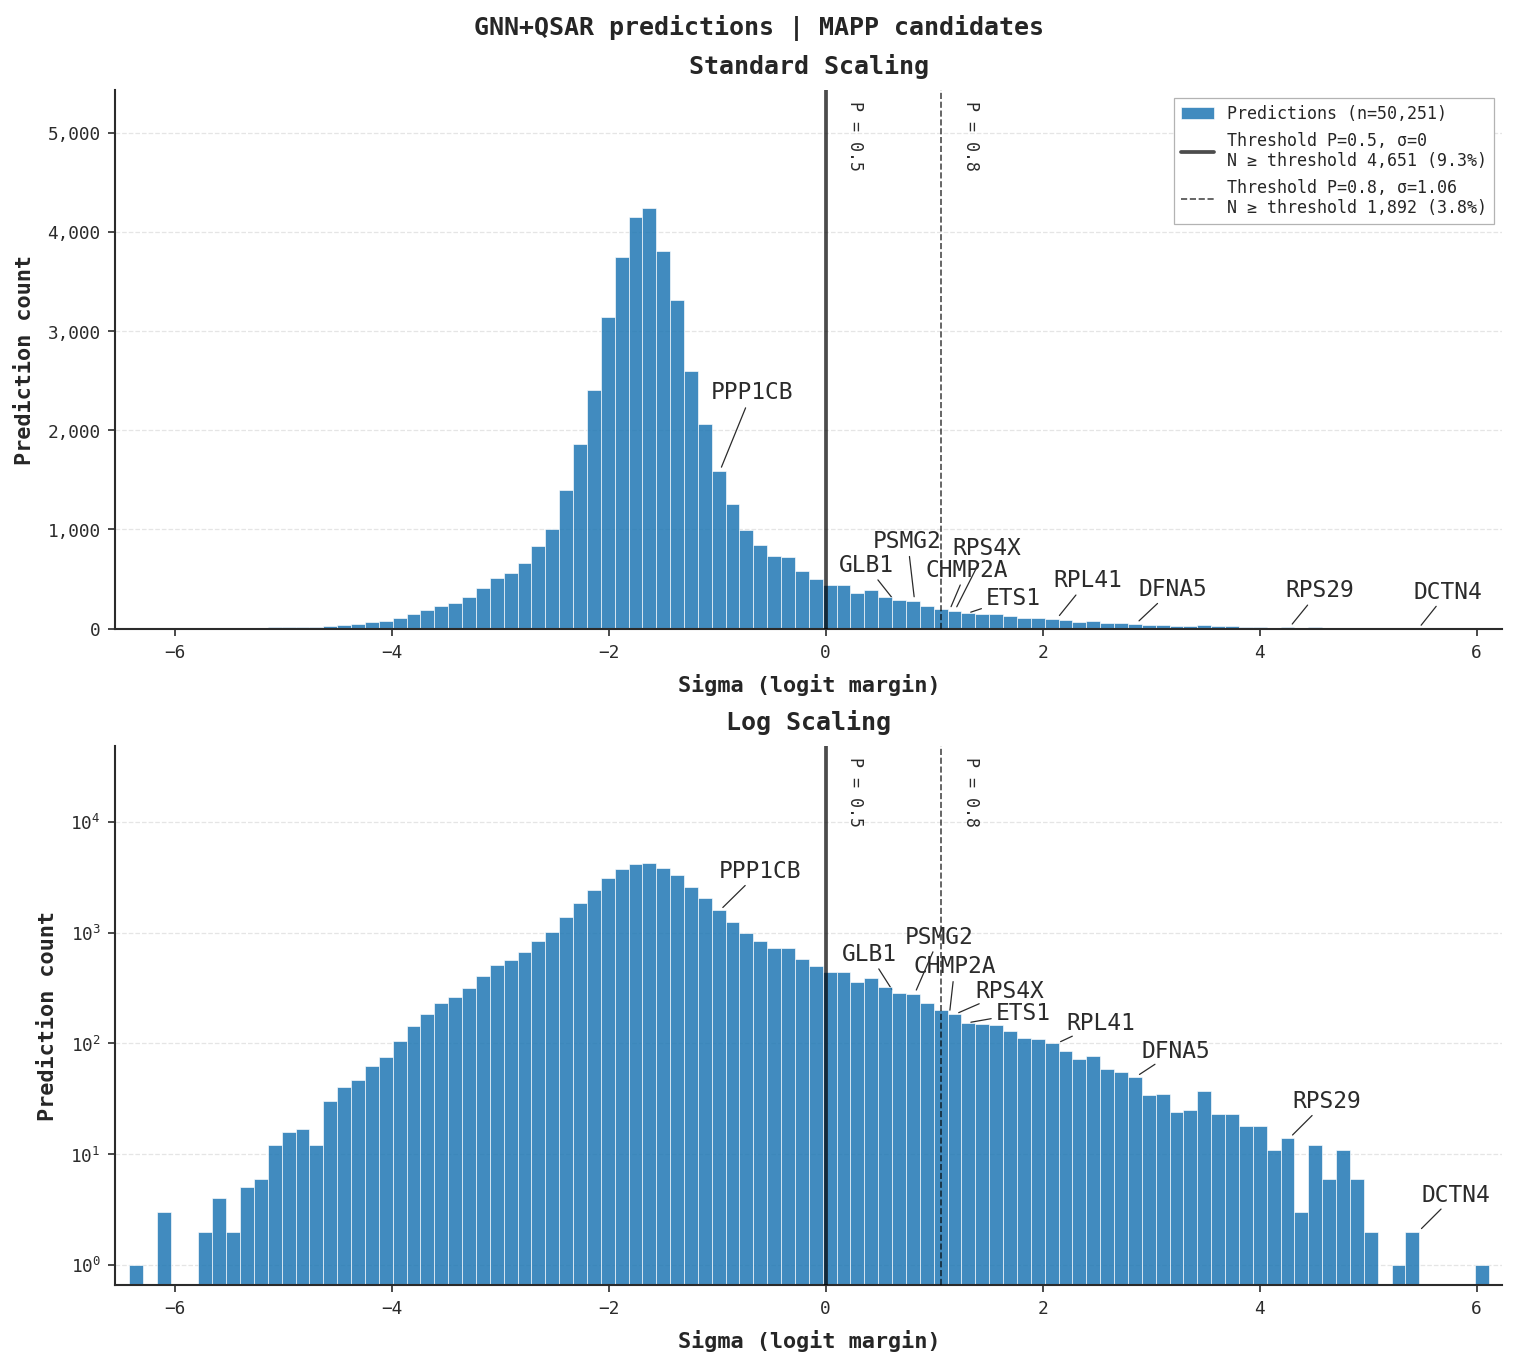

In [255]:
figure_mapp, axis_mapp = plot_prediction_distribution(predictions_50k)
plt.show()

## GNN+QSAR prediction distribution — 1,074 confirmed set

The confirmed-candidate distribution uses its own sigma range, with the same decision boundary and presentation formatting as the 465k and MAPP sets.

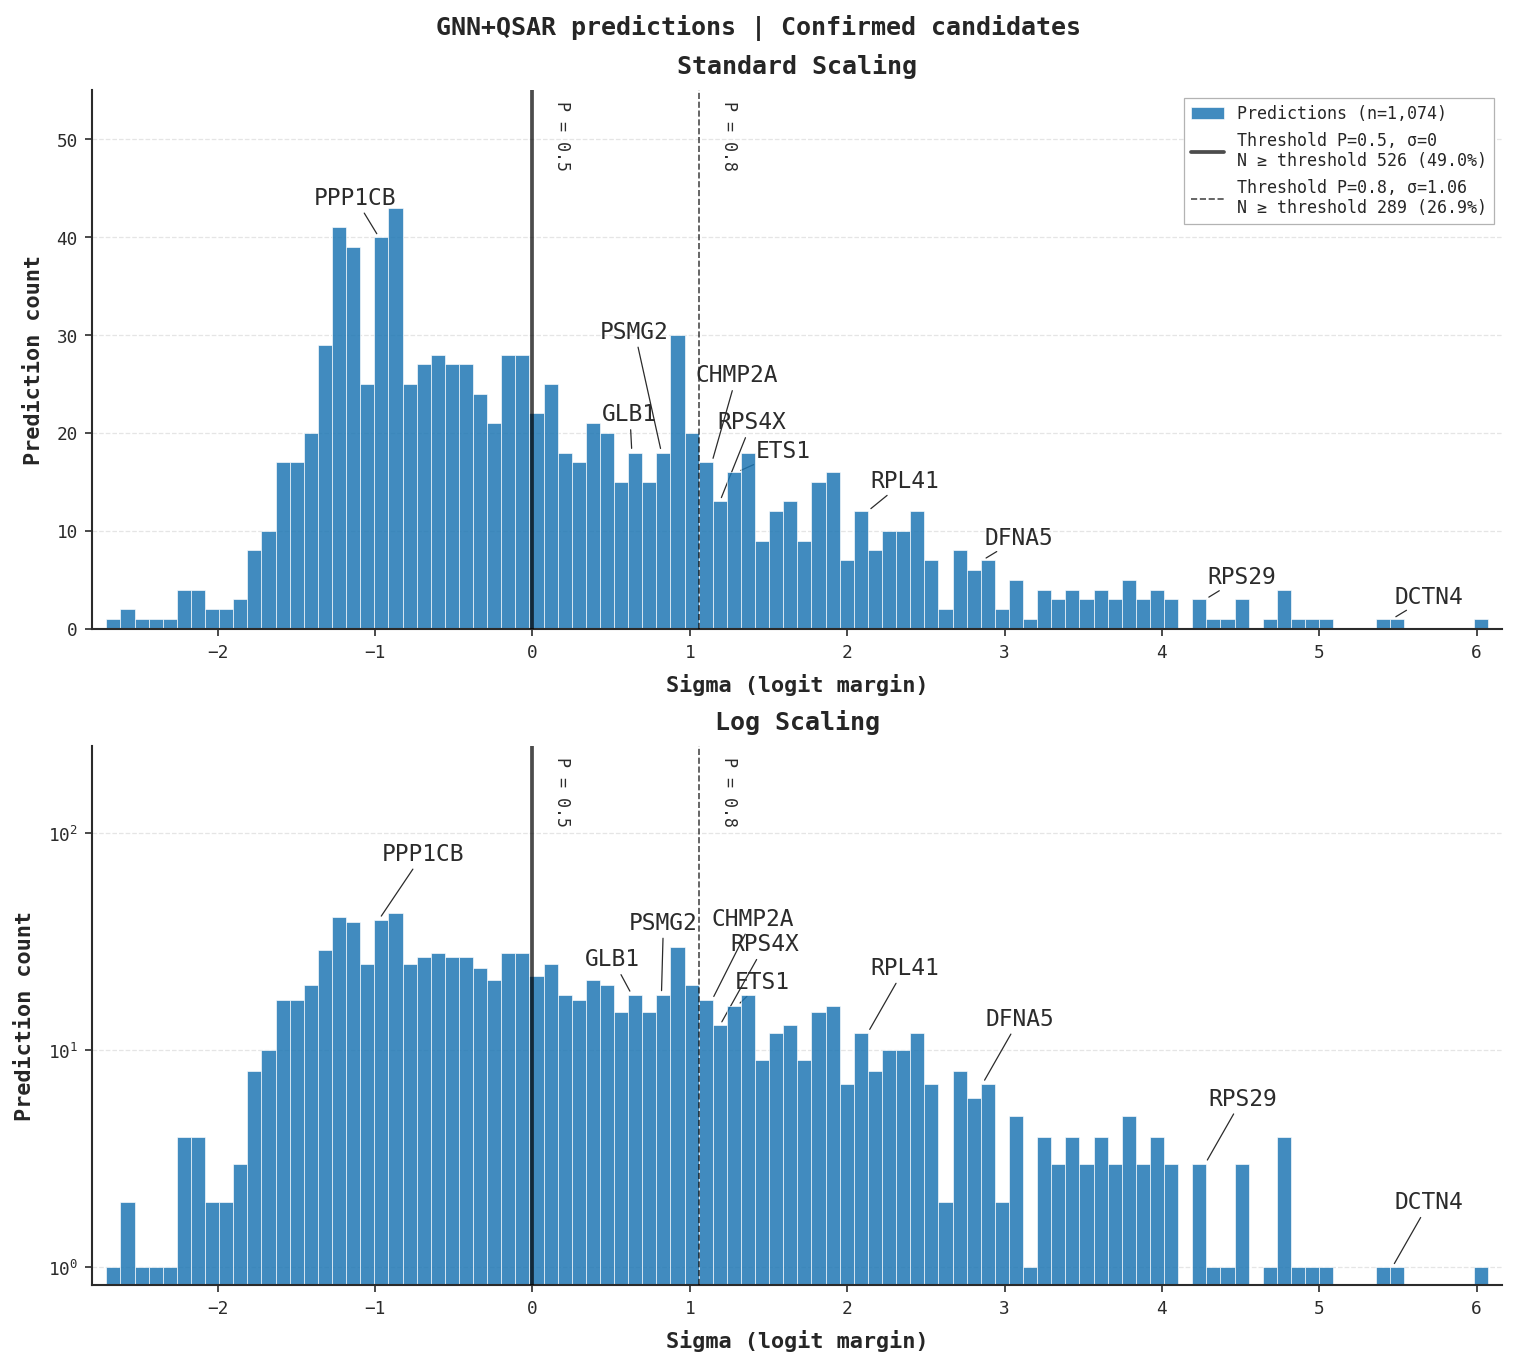

In [256]:
figure_1k, axis_1k = plot_prediction_distribution(predictions_1k)
plt.show()

## Paper-selected candidates

The 10 sequences marked on the histograms. Sigma is the GNN+QSAR logit margin in each prediction set. A blank sigma means that sequence is not in the set. All 10 are in the MAPP and confirmed sets; DFNA5, PSMG2, and RPS4X are also in the 465k set.

In [257]:
def paper_score_lookup(frame: pd.DataFrame) -> dict[str, tuple[float, float]]:
    sequence_column = find_column(frame, ("sequence", "peptide_sequence", "peptide"))
    keys = frame[sequence_column].astype("string").str.strip().str.upper()
    sigma = pd.to_numeric(frame[SIGMA_COLUMN], errors="coerce")
    probability = pd.to_numeric(frame[PROBABILITY_COLUMN], errors="coerce")
    lookup = {}
    for key, score, prob in zip(keys, sigma, probability):
        if key not in lookup and np.isfinite(score):
            lookup[key] = (float(score), float(prob) if np.isfinite(prob) else np.nan)
    return lookup


score_lookups = {key: paper_score_lookup(frame) for key, frame in prediction_results.items()}
rows = []
for sequence, label in PAPER_CANDIDATES.items():
    key = sequence.strip().upper()
    row = {"label": label, "sequence": sequence, "length": len(sequence)}
    for set_name, lookup in score_lookups.items():
        score = lookup.get(key)
        row[f"sigma_{set_name}"] = score[0] if score else np.nan
    confirmed = score_lookups["1k"].get(key)
    row["p_amp_1k"] = confirmed[1] if confirmed else np.nan
    rows.append(row)

paper_candidates = pd.DataFrame(rows)
display(
    paper_candidates.style.format(
        {
            "sigma_465k": "{:.3f}",
            "sigma_50k": "{:.3f}",
            "sigma_1k": "{:.3f}",
            "p_amp_1k": "{:.4f}",
        },
        na_rep="",
    )
)

,label,sequence,length,sigma_465k,sigma_50k,sigma_1k,p_amp_1k
0,DFNA5,SLVTKKKRFWCWQRPKYQFL,20,2.860,2.860,2.860,0.9283
1,DCTN4,SQLYPRHKHLLIKRSLRCRKC,21,,5.464,5.464,0.9978
2,RPL41,MRAKWRKKRMRRLK,14,,2.130,2.130,0.8261
3,PSMG2,RSIFIKYKSKPFCEKLLSWVKS,22,0.820,0.820,0.820,0.4396
4,GLB1,SRVPRFYWKDRLLKMKMA,18,,0.632,0.632,0.3772
5,RPS4X,LPLIIFLRNRLKY,13,1.191,1.191,1.191,0.5663
6,PPP1CB,KRRFNIKLWKTF,12,,-0.975,-0.975,0.0624
7,CHMP2A,RRYVRKFVLMR,11,,1.141,1.141,0.5493
8,ETS1,SRGLRYYYDKNIIHKTAGKRYVYRFV,26,,1.301,1.301,0.6029
9,RPS29,GHQQLYWSHPRKFGQGSRSCRVCSNRHGLIRKYGLNM,37,,4.276,4.276,0.9891


## Top five GNN+QSAR predictions

Highest sigma candidates from the 465k in-silico proteome, MAPP, and 1,074 confirmed sets. Sigma is the GNN logit margin. Sequence length is reported for each set; MAPP rows also include the parent protein accession and gene name from the deduplicated MAPP source.

In [258]:
def top_predictions(frame: pd.DataFrame, n: int = 5) -> pd.DataFrame:
    sigma_column = f"{MODEL_NAME}_logit_margin"
    probability_column = f"{MODEL_NAME}_prob_AMP"
    id_column = find_column(frame, ("peptide_id", "id"))
    sequence_column = find_column(frame, ("sequence", "peptide_sequence", "peptide"))
    columns = []
    for column in (
        id_column,
        sequence_column,
        "sequence_length",
        "parent_protein",
        "gene_name",
        sigma_column,
        probability_column,
    ):
        if column is not None and column in frame.columns and column not in columns:
            columns.append(column)

    ranked = frame.copy()
    ranked[sigma_column] = pd.to_numeric(ranked[sigma_column], errors="coerce")
    result = ranked.nlargest(n, sigma_column).loc[:, columns].copy()
    result = result.rename(columns={sigma_column: "sigma", probability_column: "predicted_p_amp"})
    result.index = pd.RangeIndex(1, len(result) + 1, name="rank")
    return result


top_5_465k = top_predictions(predictions_465k)
top_5_mapp = top_predictions(predictions_50k)
top_5_1k = top_predictions(predictions_1k)

print("465k in-silico proteome candidates")
display(top_5_465k.style.format({"sigma": "{:.4f}", "predicted_p_amp": "{:.6f}"}))
print("MAPP candidates")
display(top_5_mapp.style.format({"sigma": "{:.4f}", "predicted_p_amp": "{:.6f}"}))
print("1,074 confirmed candidates")
display(top_5_1k.style.format({"sigma": "{:.4f}", "predicted_p_amp": "{:.6f}"}))

465k in-silico proteome candidates


,peptide_id,sequence,sequence_length,sigma,predicted_p_amp
rank,,,,,
1,PEP_3652,RRRHCSRRRLHRIHRRQHRSCRRRKRRSCRHRRRHRRGCRTRKRTCRRH,49,18.7298,1.000000
2,PEP_14637,GQSHYRRRHCSRRRLHRIHRRQHRSCRRRKRRSCRHRRRHR,41,15.3354,1.000000
3,PEP_18676,RRRLHRIHRRQHRSCRRRKRRSCRHRRRHRRGCRTR,36,14.3296,1.000000
4,PEP_200642,QHRSCRRRKRRSCRHRRRHRRGCRTRKRTCRRH,33,13.3923,1.000000
5,PEP_29,KLTHLRKRIHRPRRRTTRRWKRWFKFRKRKGEKRPRPNHKAVARRAKLKF,50,12.7040,1.000000


MAPP candidates


,peptide_id,sequence,sequence_length,parent_protein,gene_name,sigma,predicted_p_amp
rank,,,,,,,
1,SEQ_10613,HRSLGRHISIVKHLRH,16,Q9Y2X7,GIT1,5.9922,0.998958
2,SEQ_17393,SQLYPRHKHLLIKRSLRCRKC,21,Q9UJW0,DCTN4,5.4642,0.997850
3,SEQ_2203,GHQQLYWSHPRKFGQGSRSCRVCSNRHGLIRKYGL,35,P62273,RPS29,5.3983,0.997646
4,SEQ_13645,VGAIIGKKGAHIKQL,15,Q9Y6M1,IGF2BP2,5.2917,0.997276
5,SEQ_33559,IGALKLN,7,Q9UNM6,PSMD13,5.0305,0.996104


1,074 confirmed candidates


,peptide_id,sequence,sequence_length,sigma,predicted_p_amp
rank,,,,,
1,SEQ_464,HRSLGRHISIVKHLRH,16,5.9922,0.998958
2,SEQ_5,SQLYPRHKHLLIKRSLRCRKC,21,5.4642,0.997850
3,SEQ_24,GHQQLYWSHPRKFGQGSRSCRVCSNRHGLIRKYGL,35,5.3983,0.997646
4,SEQ_17,GHQQLYWSHPRKFGQGSRSCRVCSNRHGLIRKYGLNMC,38,5.0254,0.996077
5,SEQ_27,YWSHPRKFGQGSRSCRVCSNRHGLIRKYGL,30,4.9292,0.995525
